[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/jhconning/hunter_eco701/blob/main/notebooks/topic02_constrained_optimization_numerical.ipynb)

# Topic 2: Constrained Optimization -- Solving It With Code

This notebook is a companion to
[`slides/02_constrained-optimization/deck.md`](../slides/02_constrained-optimization/deck.md)
(all three sub-chunks: Mathematical Preliminaries, the Tangency and Lagrange
Methods, and Applications). It is deliberately **not** a figure-replication
notebook -- that already exists at
[`topic02_constrained_optimization_figures.ipynb`](topic02_constrained_optimization_figures.ipynb)
for Part I.

Instead, this notebook does what the slides can't: it **sets up and solves**
every major constrained-optimization example from the deck as running code,
using [`sympy`](https://www.sympy.org/) for exact symbolic solutions and
[`scipy.optimize`](https://docs.scipy.org/doc/scipy/reference/optimize.html)
for numerical ones -- then checks that the two agree. Along the way it goes
a bit further than the slides do:

- a small **reusable symbolic Lagrangian solver**, so you can hand it any
  objective and constraint(s) and get the FOCs solved automatically
- a genuine **corner-solution** example solved numerically (not just
  described qualitatively)
- the Earthquake Relief problem solved **two ways** -- by hand-checking
  three cases (as the slides teach) and by handing the whole thing to
  `scipy.optimize` in one call with inequality constraints -- to show why
  the "try every case" method the slides teach is what's happening under
  the hood of a numerical solver
- a numerical check of the **shadow price** interpretation of $\lambda$
  (envelope theorem): relax a binding constraint by one unit and watch the
  objective rise by (approximately) $\lambda$

If you haven't seen `sympy` or `scipy.optimize` before, don't worry -- each
is introduced where it's first used.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
from scipy.optimize import minimize
from pathlib import Path

NAVY = "#24325c"
AMBER = "#b8842a"
TEAL = "#2a7f7f"

plt.rcParams.update({
    "font.family": "serif",
    "font.size": 12,
    "axes.edgecolor": "#333333",
    "axes.labelcolor": "#222222",
})

FIGDIR = Path("../slides/02_constrained-optimization/figs")
FIGDIR.mkdir(parents=True, exist_ok=True)

def savefig(fig, name):
    path = FIGDIR / name
    fig.savefig(path, dpi=150, bbox_inches="tight")
    print(f"saved {path}")

sp.init_printing()

## A Reusable Symbolic Lagrangian Solver

The deck's Method of Lagrange (see "Method of Lagrange: General Form") says:
to maximize $f(x_1,\dots,x_n)$ subject to constraints $g^m(x_1,\dots,x_n)=c_m$,
form

$$L = f + \sum_m \lambda_m\big(c_m - g^m\big)$$

and solve $\partial L/\partial x_i = 0$ for every choice variable *and* every
multiplier (the derivative w.r.t. $\lambda_m$ just hands back the $m$-th
constraint itself). `sympy` can do this mechanically for us, for *any*
objective and constraint we write down symbolically.

In [2]:
def lagrangian_solve(objective, constraints, variables):
    '''Solve max `objective` s.t. `constraints` (a list of sympy Eq) over `variables`.

    Returns (solutions, L) where `solutions` is sympy's list of solution
    dicts (usually one) and `L` is the Lagrangian expression itself, so you
    can inspect the FOCs or substitute the solution back in.
    '''
    n = len(constraints)
    lambdas = [sp.Symbol("lambda")] if n == 1 else list(sp.symbols(f"lambda1:{n+1}"))
    L = objective + sum(lam * (con.rhs - con.lhs) for lam, con in zip(lambdas, constraints))
    unknowns = list(variables) + lambdas
    foc = [sp.diff(L, u) for u in unknowns]
    solutions = sp.solve(foc, unknowns, dict=True)
    return solutions, L

## Worked Example 1: Utility Maximization (One Constraint)

The deck's motivating example: $\max_{c_1,c_2} u(c_1,c_2)=c_1c_2$ subject to
$p_1c_1+p_2c_2=I$. Let's hand it straight to `lagrangian_solve` and see if
it recovers the closed form from the "Solving the Cobb-Douglas Example"
slide: $c_1^*=I/(2p_1)$, $c_2^*=I/(2p_2)$.

In [3]:
c1, c2, p1, p2, I = sp.symbols("c1 c2 p1 p2 I", positive=True)

objective = c1 * c2
budget = sp.Eq(p1 * c1 + p2 * c2, I)

solutions, L = lagrangian_solve(objective, [budget], [c1, c2])
sol = solutions[0]
print("Lagrangian:  L =", L)
print()
for k, v in sol.items():
    print(f"  {k} = {sp.simplify(v)}")

Lagrangian:  L = c1*c2 + lambda*(I - c1*p1 - c2*p2)

  c1 = I/(2*p1)
  c2 = I/(2*p2)
  lambda = I/(2*p1*p2)


That matches the deck exactly: $c_1^*=\dfrac{I}{2p_1}$, $c_2^*=\dfrac{I}{2p_2}$,
and $\lambda^*=\dfrac{I}{2p_1p_2}$ (the common marginal-utility-per-dollar,
i.e. the marginal utility of income).

Now let's check this against a **numerical** solver on a concrete example,
using `scipy.optimize.minimize`. `scipy` only *minimizes*, so we minimize
$-u(c_1,c_2)$; the equality constraint is passed as a dict.

In [4]:
p1_val, p2_val, I_val = 2.0, 3.0, 120.0

def neg_utility(c):
    c1_, c2_ = c
    return -(c1_ * c2_)

budget_constraint = {
    "type": "eq",
    "fun": lambda c: p1_val * c[0] + p2_val * c[1] - I_val,
}

result = minimize(
    neg_utility, x0=[1.0, 1.0],
    constraints=[budget_constraint],
    bounds=[(0, None), (0, None)],
    method="SLSQP",
)

c1_star_formula = I_val / (2 * p1_val)
c2_star_formula = I_val / (2 * p2_val)

print(f"scipy.optimize:  c1* = {result.x[0]:.4f}, c2* = {result.x[1]:.4f}, U* = {-result.fun:.4f}")
print(f"closed form:     c1* = {c1_star_formula:.4f}, c2* = {c2_star_formula:.4f}, U* = {c1_star_formula*c2_star_formula:.4f}")

scipy.optimize:  c1* = 30.0000, c2* = 20.0000, U* = 600.0000
closed form:     c1* = 30.0000, c2* = 20.0000, U* = 600.0000


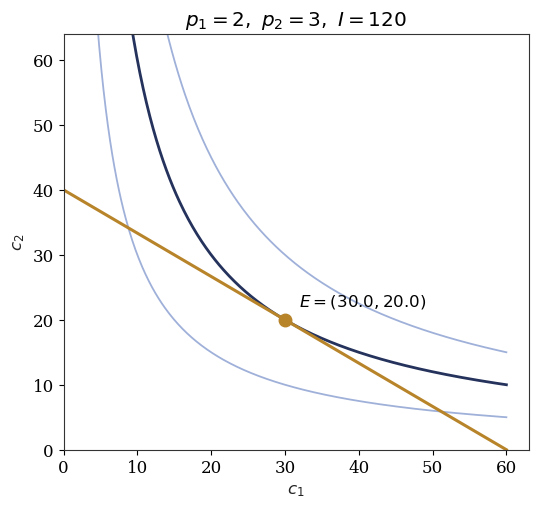

saved ..\slides\02_constrained-optimization\figs\tangency-scipy-check.png


In [5]:
def plot_tangency(p1_val, p2_val, I_val, ax=None):
    c1_star = I_val / (2 * p1_val)
    c2_star = I_val / (2 * p2_val)
    u_star = c1_star * c2_star

    show = ax is None
    if ax is None:
        fig, ax = plt.subplots(figsize=(6, 5.4))

    x = np.linspace(0.5, I_val / p1_val, 400)
    for u_level, color in zip([0.5 * u_star, u_star, 1.5 * u_star], ["#9fb0d9", NAVY, "#9fb0d9"]):
        y = u_level / x
        ax.plot(x, y, color=color, lw=2 if color == NAVY else 1.3)

    x_budget = np.linspace(0, I_val / p1_val, 200)
    y_budget = (I_val - p1_val * x_budget) / p2_val
    ax.plot(x_budget, y_budget, color=AMBER, lw=2.2)

    ax.plot(c1_star, c2_star, "o", color=AMBER, ms=9, zorder=5)
    ax.annotate(f"$E=({c1_star:.1f}, {c2_star:.1f})$", (c1_star, c2_star),
                textcoords="offset points", xytext=(10, 10))

    ax.set_xlim(0, I_val / p1_val * 1.05)
    ax.set_ylim(0, I_val / p2_val * 1.6)
    ax.set_xlabel("$c_1$"); ax.set_ylabel("$c_2$")
    ax.set_title(fr"$p_1={p1_val:g},\ p_2={p2_val:g},\ I={I_val:g}$")
    if show:
        plt.show()
        return fig

fig = plot_tangency(p1_val, p2_val, I_val)
savefig(fig, "tangency-scipy-check.png")

### Interactive: watch the tangency point move

Drag the sliders (needs a live Jupyter kernel -- Jupyter Lab/Notebook or
VS Code, not a static HTML export) to see the optimal bundle $E$ respond to
prices and income in real time. This is the same reallocation logic as the
deck's "Arbitrage Argument" slide, made tangible.

In [6]:
import ipywidgets as widgets

def _interactive_tangency(p1=2.0, p2=3.0, I=120.0):
    fig, ax = plt.subplots(figsize=(6, 5.4))
    plot_tangency(p1, p2, I, ax=ax)
    plt.show()

widgets.interact(
    _interactive_tangency,
    p1=widgets.FloatSlider(value=2.0, min=0.5, max=8, step=0.5, description="$p_1$"),
    p2=widgets.FloatSlider(value=3.0, min=0.5, max=8, step=0.5, description="$p_2$"),
    I=widgets.FloatSlider(value=120.0, min=20, max=300, step=10, description="$I$"),
);

interactive(children=(FloatSlider(value=2.0, description='$p_1$', max=8.0, min=0.5, step=0.5), FloatSlider(val…

## Worked Example 2: The General Lagrangian -- Labor Allocation Along a PPF

The deck's "Application: Labor Allocation and a PPF" slide keeps $U(x_1,x_2)$
generic and only derives the FOC ratio $u_1/u_2 = MPL_2/MPL_1$. Let's make it
concrete with $U(x_1,x_2)=x_1x_2$ again (same reusable solver, different
constraint) and see that the structure is *identical* to the budget problem
above with "prices" $1/MPL_1,\,1/MPL_2$ and "income" $\bar L$.

In [7]:
x1, x2, MPL1, MPL2, Lbar = sp.symbols("x1 x2 MPL1 MPL2 Lbar", positive=True)

ppf_objective = x1 * x2
ppf_constraint = sp.Eq(x1 / MPL1 + x2 / MPL2, Lbar)

ppf_solutions, ppf_L = lagrangian_solve(ppf_objective, [ppf_constraint], [x1, x2])
ppf_sol = ppf_solutions[0]
for k, v in ppf_sol.items():
    print(f"  {k} = {sp.simplify(v)}")

# Sanity check against the deck's stated relationship: lambda = u1*MPL1 = u2*MPL2
u1 = sp.diff(ppf_objective, x1).subs(ppf_sol)
u2 = sp.diff(ppf_objective, x2).subs(ppf_sol)
lam = ppf_sol[sp.Symbol("lambda")]
print()
print("u1*MPL1 - lambda simplifies to:", sp.simplify(u1 * MPL1 - lam))
print("u2*MPL2 - lambda simplifies to:", sp.simplify(u2 * MPL2 - lam))

  lambda = Lbar*MPL1*MPL2/2
  x1 = Lbar*MPL1/2
  x2 = Lbar*MPL2/2

u1*MPL1 - lambda simplifies to: 0
u2*MPL2 - lambda simplifies to: 0


Both differences simplify to `0` -- confirming $\lambda = u_1\cdot MPL_1 =
u_2\cdot MPL_2$, exactly as the slide states. Now a concrete numeric example
and a plot in the same style as `constrained-max-graph.png`.

scipy.optimize:  x1* = 100.0000, x2* = 50.0000
closed form:     x1* = 100.0000, x2* = 50.0000


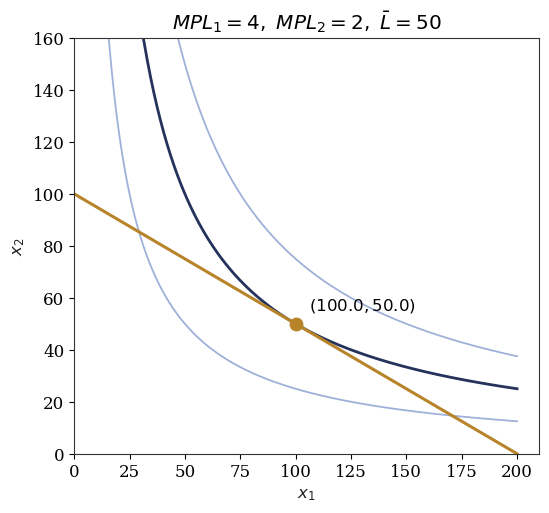

saved ..\slides\02_constrained-optimization\figs\ppf-scipy-check.png


In [8]:
MPL1_val, MPL2_val, Lbar_val = 4.0, 2.0, 50.0

def neg_output(x):
    return -(x[0] * x[1])

ppf_numeric_constraint = {
    "type": "eq",
    "fun": lambda x: x[0] / MPL1_val + x[1] / MPL2_val - Lbar_val,
}
ppf_result = minimize(
    neg_output, x0=[1.0, 1.0],
    constraints=[ppf_numeric_constraint],
    bounds=[(0, None), (0, None)],
    method="SLSQP",
)

x1_formula = ppf_sol[x1].subs({MPL1: MPL1_val, MPL2: MPL2_val, Lbar: Lbar_val})
x2_formula = ppf_sol[x2].subs({MPL1: MPL1_val, MPL2: MPL2_val, Lbar: Lbar_val})
print(f"scipy.optimize:  x1* = {ppf_result.x[0]:.4f}, x2* = {ppf_result.x[1]:.4f}")
print(f"closed form:     x1* = {float(x1_formula):.4f}, x2* = {float(x2_formula):.4f}")

fig, ax = plt.subplots(figsize=(6, 5.4))
x1_star, x2_star = ppf_result.x
x_range = np.linspace(0.5, Lbar_val * MPL1_val, 400)
for level, color in zip([0.5, 1.0, 1.5], ["#9fb0d9", NAVY, "#9fb0d9"]):
    u_level = level * (x1_star * x2_star)
    ax.plot(x_range, u_level / x_range, color=color, lw=2 if color == NAVY else 1.3)

x_ppf = np.linspace(0, Lbar_val * MPL1_val, 200)
x2_ppf = MPL2_val * (Lbar_val - x_ppf / MPL1_val)
ax.plot(x_ppf, x2_ppf, color=AMBER, lw=2.2)
ax.plot(x1_star, x2_star, "o", color=AMBER, ms=9, zorder=5)
ax.annotate(f"$({x1_star:.1f}, {x2_star:.1f})$", (x1_star, x2_star),
            textcoords="offset points", xytext=(10, 10))
ax.set_xlim(0, Lbar_val * MPL1_val * 1.05)
ax.set_ylim(0, Lbar_val * MPL2_val * 1.6)
ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$")
ax.set_title(fr"$MPL_1={MPL1_val:g},\ MPL_2={MPL2_val:g},\ \bar L={Lbar_val:g}$")
plt.show()
savefig(fig, "ppf-scipy-check.png")

## Worked Example 3: A Genuine Corner Solution

The deck's "Example: A Corner Solution" slide describes the *condition*
for a corner ($MU_1/MU_2 < p_1/p_2$ everywhere) but doesn't solve one
numerically. Here's a utility function where a corner genuinely emerges:
$u(c_1,c_2) = c_1 + \sqrt{c_2}$ -- good 1 has **constant** marginal utility
($MU_1=1$ always), so once good 1 is expensive enough relative to that flat
marginal benefit, it's optimal to buy *none* of it.

With $p_1=5,\ p_2=1,\ I=2$: the interior tangency condition would require
$c_2=(p_1/2p_2)^2=6.25$, which alone costs $p_2c_2=6.25 > I=2$ -- infeasible.
So we expect `scipy` to land on the corner $c_1^*=0$.

In [9]:
def neg_utility_corner(c):
    c1_, c2_ = c
    return -(c1_ + np.sqrt(c2_))

p1_corner, p2_corner, I_corner = 5.0, 1.0, 2.0
corner_constraint = {
    "type": "eq",
    "fun": lambda c: p1_corner * c[0] + p2_corner * c[1] - I_corner,
}
corner_result = minimize(
    neg_utility_corner, x0=[0.2, 0.2],
    constraints=[corner_constraint],
    bounds=[(0, None), (0, None)],
    method="SLSQP",
)
print(f"scipy.optimize:  c1* = {corner_result.x[0]:.4f}, c2* = {corner_result.x[1]:.4f}")
print("Hand-derived corner: c1* = 0, c2* = I/p2 =", I_corner / p2_corner)

# Verify the corner FOC inequality holds: MU1 - lambda*p1 <= 0 at the corner
c2_at_corner = I_corner / p2_corner
mu1 = 1.0
mu2 = 0.5 / np.sqrt(c2_at_corner)
lam_corner = mu2 / p2_corner
print(f"\nAt the corner: MU1={mu1:.4f}, MU2={mu2:.4f}, lambda={lam_corner:.4f}")
print(f"MU1 - lambda*p1 = {mu1 - lam_corner*p1_corner:.4f}  (should be <= 0 for a corner)")

scipy.optimize:  c1* = 0.0000, c2* = 2.0000
Hand-derived corner: c1* = 0, c2* = I/p2 = 2.0

At the corner: MU1=1.0000, MU2=0.3536, lambda=0.3536
MU1 - lambda*p1 = -0.7678  (should be <= 0 for a corner)


Both checks agree: `scipy` finds $c_1^*\approx 0$, and the complementary-
slackness condition $\partial L/\partial c_1 = MU_1-\lambda p_1\le 0$ holds
at that corner, exactly the condition the "Complementary Slackness" slide
describes.

## Worked Example 4: Multiple Constraints -- The Earthquake Relief Problem

This is the deck's big set-piece (Problem Set 1, Q3):

$$\max_{c_F,c_W} U(c_F,c_W)=c_F\cdot c_W \quad\text{s.t.}\quad p_Fc_F+p_Wc_W\le I,\quad c_F+c_W\le T$$

with $p_F=1,\ p_W=2,\ I=100,\ T=80$. The slides teach solving it by checking
three cases by hand and discarding infeasible candidates. Let's do that in
code first, then see what happens when we just hand the whole problem --
inequality constraints and all -- to a numerical solver in one shot.

### Case by case, symbolically

In [10]:
cF, cW, pF, pW, Iv, Tv = sp.symbols("cF cW pF pW Iv Tv", positive=True)
pF_val, pW_val, I_val_eq, T_val = 1.0, 2.0, 100.0, 80.0
subs_vals = {pF: pF_val, pW: pW_val, Iv: I_val_eq, Tv: T_val}

objective_eq = cF * cW
budget_eq = sp.Eq(pF * cF + pW * cW, Iv)
transport_eq = sp.Eq(cF + cW, Tv)

cases = {}

# Case 1: budget binds only (mu = 0)
sol1, _ = lagrangian_solve(objective_eq, [budget_eq], [cF, cW])
cases["budget binds only"] = {k: v.subs(subs_vals) for k, v in sol1[0].items()}

# Case 2: transport binds only (lambda = 0)
sol2, _ = lagrangian_solve(objective_eq, [transport_eq], [cF, cW])
cases["transport binds only"] = {k: v.subs(subs_vals) for k, v in sol2[0].items()}

# Case 3: both bind -- no optimization needed, just solve the two constraints
sol3 = sp.solve([budget_eq.subs(subs_vals), transport_eq.subs(subs_vals)], [cF, cW], dict=True)[0]
cases["both bind"] = sol3

def feasible(cF_val, cW_val):
    budget_ok = pF_val * cF_val + pW_val * cW_val <= I_val_eq + 1e-9
    transport_ok = cF_val + cW_val <= T_val + 1e-9
    return budget_ok, transport_ok

print(f"{'case':22s} {'(cW*, cF*)':18s} {'budget ok':10s} {'transport ok':13s} {'U':>8s}")
for name, sol in cases.items():
    cF_v, cW_v = float(sol[cF]), float(sol[cW])
    b_ok, t_ok = feasible(cF_v, cW_v)
    U_v = cF_v * cW_v
    print(f"{name:22s} ({cW_v:5.1f}, {cF_v:5.1f})   {str(b_ok):10s} {str(t_ok):13s} {U_v:8.1f}")

case                   (cW*, cF*)         budget ok  transport ok         U
budget binds only      ( 25.0,  50.0)   True       True            1250.0
transport binds only   ( 40.0,  40.0)   False      True            1600.0
both bind              ( 20.0,  60.0)   True       True            1200.0


Same table as the deck's "Worked Example: Choosing the Winner" slide:
`transport binds only` is thrown out (violates the budget), and between the
two feasible candidates, `budget binds only` wins with $U^*=1250$.

### Now: hand the whole problem to `scipy.optimize` at once

No case-checking -- just the objective and *both* constraints as
inequalities, plus non-negativity bounds.

In [11]:
def neg_U_eq(c):
    return -(c[0] * c[1])

constraints_eq = [
    {"type": "ineq", "fun": lambda c: I_val_eq - (pF_val * c[0] + pW_val * c[1])},   # budget: I - pF*cF - pW*cW >= 0
    {"type": "ineq", "fun": lambda c: T_val - (c[0] + c[1])},                          # transport: T - cF - cW >= 0
]

eq_result = minimize(
    neg_U_eq, x0=[10.0, 10.0],
    constraints=constraints_eq,
    bounds=[(0, None), (0, None)],
    method="SLSQP",
)
print(f"scipy (one shot):  cW* = {eq_result.x[1]:.4f}, cF* = {eq_result.x[0]:.4f}, U* = {-eq_result.fun:.4f}")
print("hand-derived:       cW* = 25.0000, cF* = 50.0000, U* = 1250.0000")

scipy (one shot):  cW* = 25.0000, cF* = 50.0000, U* = 1250.0000
hand-derived:       cW* = 25.0000, cF* = 50.0000, U* = 1250.0000


`scipy.optimize` lands on the same answer directly -- internally, SLSQP is
doing something conceptually similar to the case-check (working out which
constraints are active), just via an iterative algorithm rather than
enumerating cases by hand. For two constraints, three cases is nothing; for
a real-world problem with dozens of constraints, this is *why* we let the
computer do it.

### Checking the shadow-price interpretation of $\lambda$

The budget constraint binds at the optimum ($\lambda>0$), so the envelope
theorem says relaxing it by \$1 should raise utility by *approximately*
$\lambda$. Let's check by literally re-solving with $I=101$ instead of
computing $\lambda$ analytically.

In [12]:
lam_budget_only = cases["budget binds only"][sp.Symbol("lambda")] if False else None
# lambda for the "budget binds only" case, from the general formula derived in Worked Example 1:
lam_theory = I_val_eq / (2 * pF_val * pW_val)

def neg_U_eq_I(c, I_local):
    return -(c[0] * c[1])

def solve_for_I(I_local):
    cons = [
        {"type": "ineq", "fun": lambda c: I_local - (pF_val * c[0] + pW_val * c[1])},
        {"type": "ineq", "fun": lambda c: T_val - (c[0] + c[1])},
    ]
    res = minimize(neg_U_eq_I, x0=[10.0, 10.0], args=(I_local,), constraints=cons,
                    bounds=[(0, None), (0, None)], method="SLSQP")
    return -res.fun

U_at_100 = solve_for_I(100.0)
U_at_101 = solve_for_I(101.0)
print(f"U*(I=100) = {U_at_100:.4f}")
print(f"U*(I=101) = {U_at_101:.4f}")
print(f"numerical dU/dI  ~ {U_at_101 - U_at_100:.4f}")
print(f"lambda (theory)  = {lam_theory:.4f}")

U*(I=100) = 1250.0000
U*(I=101) = 1275.1250
numerical dU/dI  ~ 25.1250
lambda (theory)  = 25.0000


The numerical change in utility from one more dollar of budget lands right
next to $\lambda$ -- confirming the deck's interpretation of the multiplier
as "the value of relaxing the constraint," not just an algebraic
byproduct of the Lagrangian.

By contrast, since the *transport* constraint is slack at this optimum
($\mu=0$), relaxing it should do **nothing** -- there's spare boat capacity
already.

In [13]:
def solve_for_T(T_local):
    cons = [
        {"type": "ineq", "fun": lambda c: I_val_eq - (pF_val * c[0] + pW_val * c[1])},
        {"type": "ineq", "fun": lambda c: T_local - (c[0] + c[1])},
    ]
    res = minimize(neg_U_eq, x0=[10.0, 10.0], constraints=cons,
                    bounds=[(0, None), (0, None)], method="SLSQP")
    return -res.fun

U_at_T80 = solve_for_T(80.0)
U_at_T81 = solve_for_T(81.0)
print(f"U*(T=80) = {U_at_T80:.4f}")
print(f"U*(T=81) = {U_at_T81:.4f}")
print(f"numerical dU/dT ~ {U_at_T81 - U_at_T80:.6f}  (should be ~0 -- the constraint is slack)")

U*(T=80) = 1250.0000
U*(T=81) = 1250.0000
numerical dU/dT ~ 0.000000  (should be ~0 -- the constraint is slack)


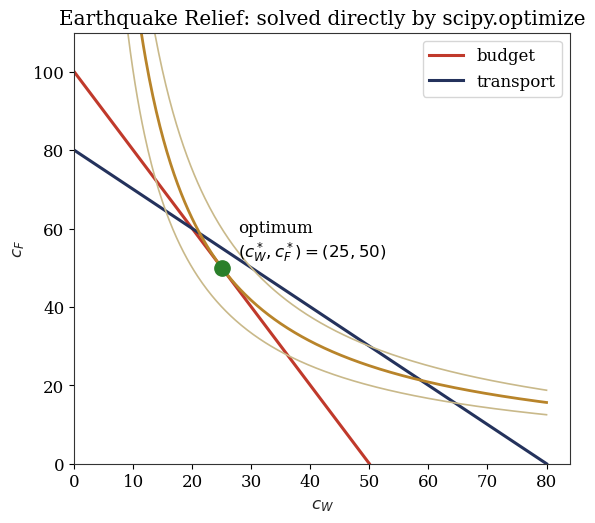

saved ..\slides\02_constrained-optimization\figs\earthquake-scipy-solution.png


In [14]:
fig, ax = plt.subplots(figsize=(6.4, 5.6))
cW_range = np.linspace(0.1, T_val, 400)
cF_budget = (I_val_eq - pW_val * cW_range) / pF_val
cF_transport = T_val - cW_range
ax.plot(cW_range[cF_budget >= 0], cF_budget[cF_budget >= 0], color="#c0392b", lw=2.2, label="budget")
ax.plot(cW_range, cF_transport, color=NAVY, lw=2.2, label="transport")

cF_star, cW_star = eq_result.x
u_star_eq = cF_star * cW_star
for level, color in zip([0.8, 1.0, 1.2], ["#c9b98a", AMBER, "#c9b98a"]):
    u_level = level * u_star_eq
    with np.errstate(divide="ignore"):
        cf_curve = u_level / cW_range
    ax.plot(cW_range, cf_curve, color=color, lw=2 if color == AMBER else 1.2)

ax.plot(cW_star, cF_star, "o", color="#2a7f2a", ms=11, zorder=5)
ax.annotate(f"optimum\n$(c_W^*,c_F^*)=({cW_star:.0f},{cF_star:.0f})$", (cW_star, cF_star),
            textcoords="offset points", xytext=(12, 8))
ax.set_xlim(0, T_val * 1.05)
ax.set_ylim(0, 100 * 1.1)
ax.set_xlabel("$c_W$"); ax.set_ylabel("$c_F$")
ax.legend(loc="upper right")
ax.set_title("Earthquake Relief: solved directly by scipy.optimize")
plt.show()
savefig(fig, "earthquake-scipy-solution.png")

## Summary

| Deck example | Symbolic (`sympy`) | Numerical (`scipy.optimize`) |
|---|---|---|
| Utility max, 1 constraint | closed form $I/2p_1,\,I/2p_2$ | matches |
| PPF / labor allocation | closed form, $\lambda=u_1MPL_1=u_2MPL_2$ verified | matches |
| Corner solution | complementary slackness checked by hand | `scipy` lands on the corner directly |
| Earthquake Relief (2 constraints) | 3 cases solved and filtered by hand | one `scipy` call, no case-checking needed |
| Shadow price of $\lambda$ | -- | confirmed numerically via envelope theorem |

Everything here generalizes: `lagrangian_solve` works for any objective and
equality constraints you can write in `sympy`, and the `scipy.optimize`
pattern (objective, `ineq`/`eq` constraints, bounds, `SLSQP`) extends to
any number of constraints and choice variables -- which is exactly the
point the deck's "As a Practical Matter" and "The Art of the Solve" slides
are making: for real problems, you reach for exactly these tools rather
than grinding through cases by hand.

See [`topic02_constrained_optimization_figures.ipynb`](topic02_constrained_optimization_figures.ipynb)
for the companion notebook that regenerates Part I's static figures.